# KitchenAid 5KSB555 Coupler (W10279256)
Parametric replacement coupler model.

In [1]:
import math

import cadquery as cq
import matplotlib.pyplot as plt
from IPython.display import HTML, display

from params import *

print(f"CadQuery {cq.__version__}")

CadQuery 2.8.0


## Parameters

In [2]:
print(f"Stem: \u00d8{lower_stem_od} x {lower_stem_height}mm")
print(f"Body: \u00d8{upper_body_od} x {upper_body_height}mm")
print(f"Flange: \u00d8{flange_od} x {flange_height}mm")
print(
    f"Insert: hex {insert_hex_flat_to_flat}mm f-f, circles \u00d8{insert_circle_dia}mm, {insert_thickness}mm thick"
)
print(
    f"Spline: {spline_teeth_count} teeth, \u00d8{spline_cavity_dia}mm, {spline_cavity_depth}mm deep"
)

Stem: Ø21.5 x 7.1mm
Body: Ø30.6 x 14.4mm
Flange: Ø45.25 x 4.0mm
Insert: hex 14.0mm f-f, circles Ø2.2mm, 7.7mm thick
Spline: 12 teeth, Ø24.0mm, 15.0mm deep


## Side cross-section with dimensions

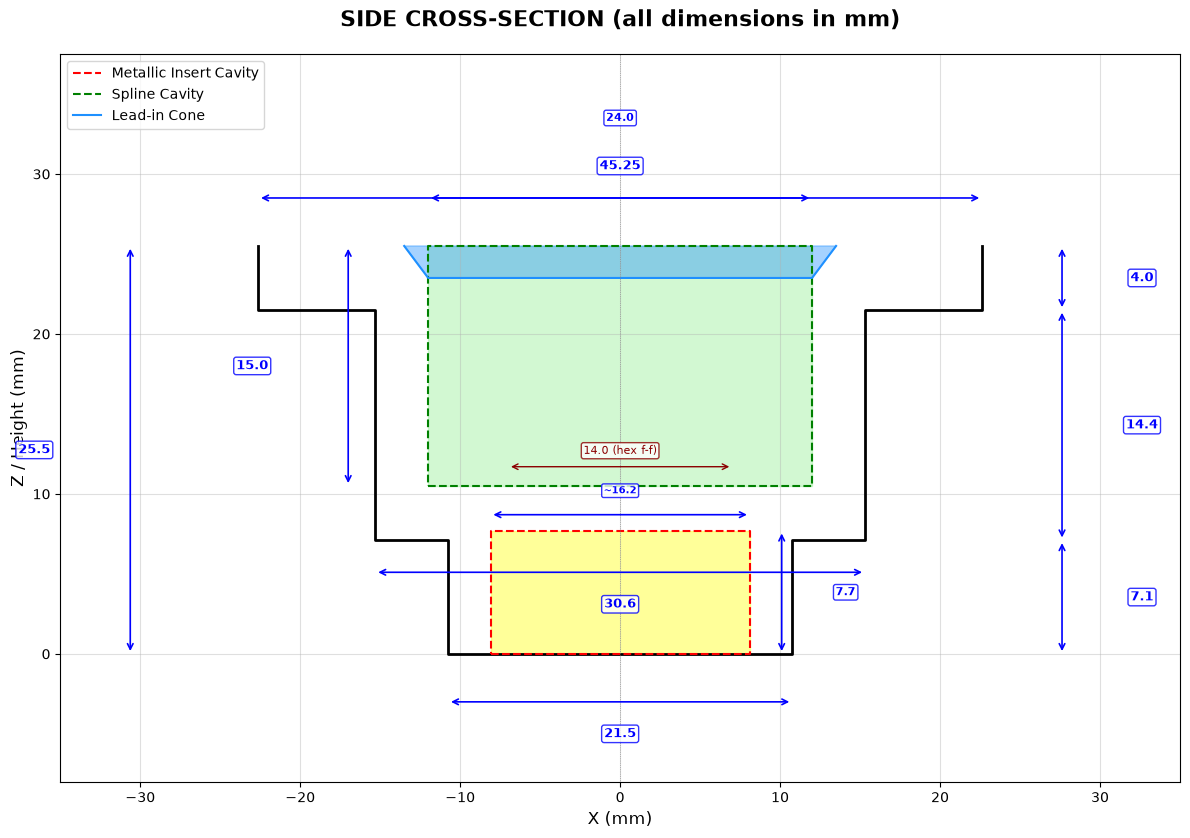

In [3]:
def dim_arrow(
    ax, x1, y1, x2, y2, text, offset_x=0, offset_y=0, fontsize=9, color="blue"
):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops={"arrowstyle": "<->", "color": color, "lw": 1.2},
    )
    mx = (x1 + x2) / 2 + offset_x
    my = (y1 + y2) / 2 + offset_y
    ax.text(
        mx,
        my,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color=color,
        fontweight="bold",
        bbox={
            "boxstyle": "round,pad=0.2",
            "facecolor": "white",
            "edgecolor": color,
            "alpha": 0.8,
        },
    )


fig, ax = plt.subplots(1, 1, figsize=(12, 14))
ax.set_aspect("equal")
ax.set_title(
    "SIDE CROSS-SECTION (all dimensions in mm)", fontsize=16, fontweight="bold", pad=20
)

rx = [
    lower_stem_od / 2,
    lower_stem_od / 2,
    upper_body_od / 2,
    upper_body_od / 2,
    flange_od / 2,
    flange_od / 2,
]
ry = [0, z_stem_top, z_stem_top, z_upper_top, z_upper_top, body_top]
px = [-x for x in reversed(rx)] + rx
py = list(reversed(ry)) + ry
ax.plot(px, py, "k-", linewidth=2)

insert_od = insert_hex_flat_to_flat + insert_circle_dia
ix = [-insert_od / 2, insert_od / 2, insert_od / 2, -insert_od / 2, -insert_od / 2]
iy = [0, 0, insert_thickness, insert_thickness, 0]
ax.fill(ix, iy, color="yellow", alpha=0.4)
ax.plot(ix, iy, "r--", linewidth=1.5, label="Metallic Insert Cavity")

spline_r = spline_cavity_dia / 2
sx = [-spline_r, spline_r, spline_r, -spline_r, -spline_r]
sy = [
    body_top - spline_cavity_depth,
    body_top - spline_cavity_depth,
    body_top,
    body_top,
    body_top - spline_cavity_depth,
]
ax.fill(sx, sy, color="lightgreen", alpha=0.4)
ax.plot(sx, sy, "g--", linewidth=1.5, label="Spline Cavity")
li_r_top = lead_in_dia / 2
li_r_bot = spline_cavity_dia / 2
li_x = [-li_r_top, -li_r_bot, li_r_bot, li_r_top, li_r_top]
li_y = [
    body_top,
    body_top - lead_in_depth,
    body_top - lead_in_depth,
    body_top,
    body_top,
]
ax.fill(li_x, li_y, color="dodgerblue", alpha=0.4)
ax.plot(li_x, li_y, color="dodgerblue", linewidth=1.5, label="Lead-in Cone")
ax.axvline(x=0, color="gray", linestyle=":", linewidth=0.5)

dim_arrow(
    ax, -lower_stem_od / 2, -3, lower_stem_od / 2, -3, f"{lower_stem_od}", offset_y=-2
)
dim_arrow(
    ax,
    flange_od / 2 + 5,
    0,
    flange_od / 2 + 5,
    z_stem_top,
    f"{lower_stem_height}",
    offset_x=5,
)
dim_arrow(
    ax,
    -upper_body_od / 2,
    z_stem_top - 2,
    upper_body_od / 2,
    z_stem_top - 2,
    f"{upper_body_od}",
    offset_y=-2,
)
dim_arrow(
    ax,
    flange_od / 2 + 5,
    z_stem_top,
    flange_od / 2 + 5,
    z_upper_top,
    f"{upper_body_height}",
    offset_x=5,
)
dim_arrow(
    ax,
    -flange_od / 2,
    body_top + 3,
    flange_od / 2,
    body_top + 3,
    f"{flange_od}",
    offset_y=2,
)
dim_arrow(
    ax,
    flange_od / 2 + 5,
    z_upper_top,
    flange_od / 2 + 5,
    body_top,
    f"{flange_height}",
    offset_x=5,
)
dim_arrow(
    ax, -flange_od / 2 - 8, 0, -flange_od / 2 - 8, body_top, f"{body_top}", offset_x=-6
)

ax.annotate(
    "",
    xy=(-insert_hex_flat_to_flat / 2, insert_thickness + 4),
    xytext=(insert_hex_flat_to_flat / 2, insert_thickness + 4),
    arrowprops={"arrowstyle": "<->", "color": "darkred", "lw": 1},
)
ax.text(
    0,
    insert_thickness + 5,
    f"{insert_hex_flat_to_flat} (hex f-f)",
    ha="center",
    va="center",
    fontsize=8,
    color="darkred",
    bbox={
        "boxstyle": "round,pad=0.2",
        "facecolor": "white",
        "edgecolor": "darkred",
        "alpha": 0.8,
    },
)
dim_arrow(
    ax,
    -insert_od / 2,
    insert_thickness + 1,
    insert_od / 2,
    insert_thickness + 1,
    f"~{insert_od:.1f}",
    offset_y=1.5,
    fontsize=7,
)
dim_arrow(
    ax,
    insert_od / 2 + 2,
    0,
    insert_od / 2 + 2,
    insert_thickness,
    f"{insert_thickness}",
    offset_x=4,
    fontsize=8,
)

dim_arrow(
    ax,
    -spline_r,
    body_top + 3,
    spline_r,
    body_top + 3,
    f"{spline_cavity_dia}",
    offset_y=5,
    fontsize=8,
)
dim_arrow(
    ax,
    -spline_r - 5,
    body_top - spline_cavity_depth,
    -spline_r - 5,
    body_top,
    f"{spline_cavity_depth}",
    offset_x=-6,
)

ax.set_xlim(-35, 35)
ax.set_ylim(-8, body_top + 12)
ax.set_xlabel("X (mm)", fontsize=12)
ax.set_ylabel("Z / Height (mm)", fontsize=12)
ax.grid(True, alpha=0.4)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Top cross-section with dimensions

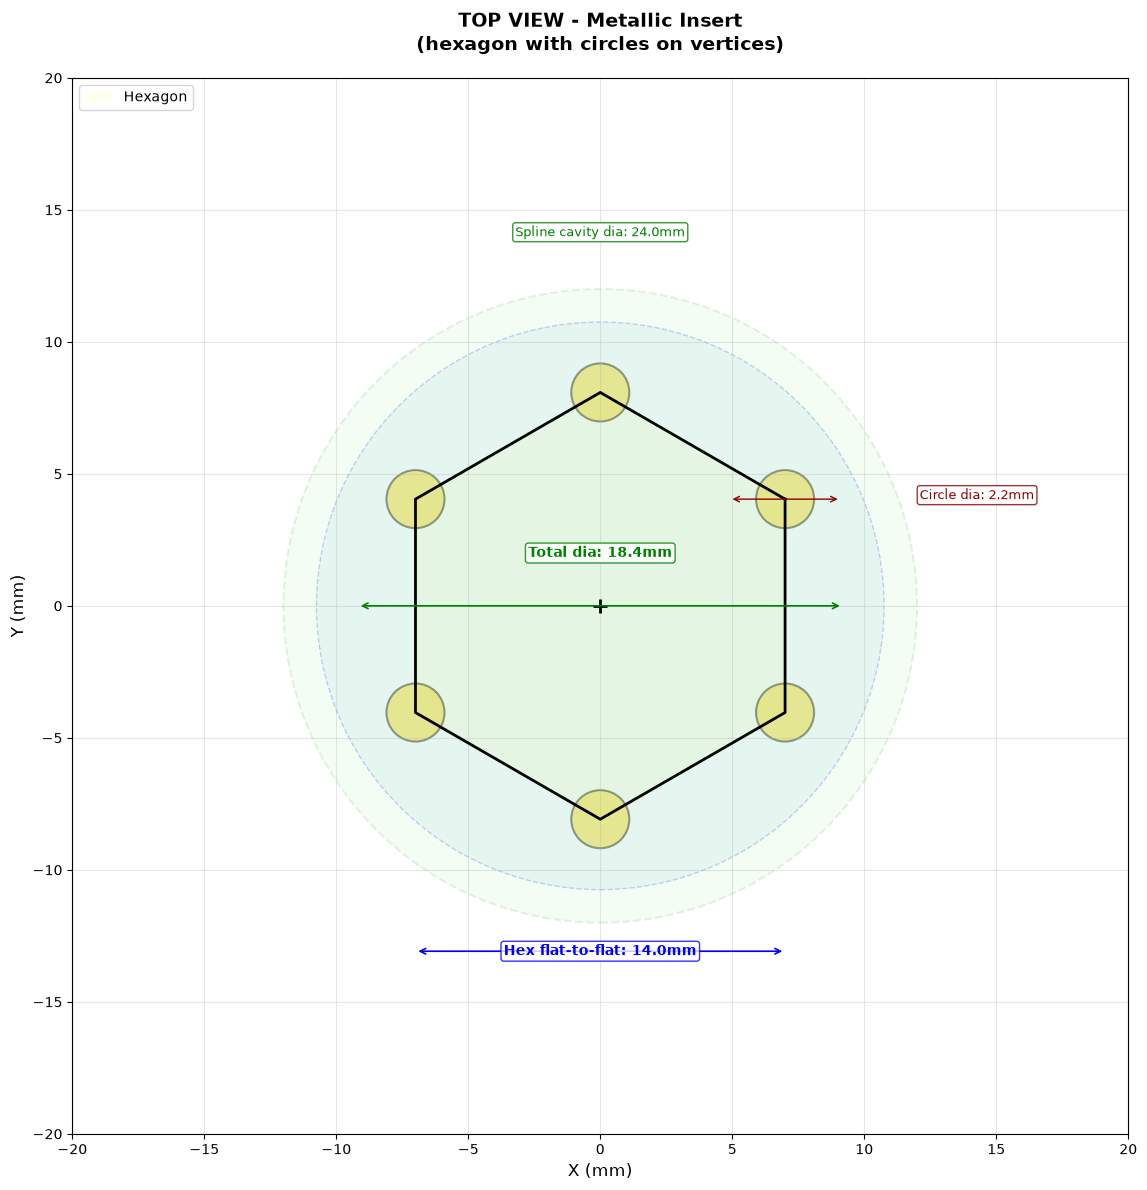

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(12, 12))
ax.set_aspect("equal")
ax.set_title(
    "TOP VIEW - Metallic Insert\n(hexagon with circles on vertices)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

hex_corner_r = insert_hex_flat_to_flat / (2 * math.cos(math.pi / 6))
circle_r = insert_circle_dia / 2

hx, hy = [], []
for i in range(6):
    angle = 2 * math.pi * i / 6 + math.pi / 6
    hx.append(hex_corner_r * math.cos(angle))
    hy.append(hex_corner_r * math.sin(angle))
hx.append(hx[0])
hy.append(hy[0])
ax.plot(hx, hy, "k-", linewidth=2)
ax.fill(hx, hy, color="lightyellow", alpha=0.5, label="Hexagon")

for i in range(6):
    angle = 2 * math.pi * i / 6 + math.pi / 6
    cx = hex_corner_r * math.cos(angle)
    cy = hex_corner_r * math.sin(angle)
    circle = plt.Circle(
        (cx, cy),
        circle_r,
        facecolor="gold",
        alpha=0.5,
        edgecolor="black",
        linewidth=1.5,
    )
    ax.add_patch(circle)

stem_r = lower_stem_od / 2
ax.add_patch(
    plt.Circle(
        (0, 0),
        stem_r,
        facecolor="lightblue",
        alpha=0.2,
        edgecolor="blue",
        linewidth=1,
        linestyle="--",
    )
)
ax.plot(0, 0, "k+", markersize=10, markeredgewidth=2)

dim_arrow(
    ax,
    -insert_hex_flat_to_flat / 2,
    -hex_corner_r - 5,
    insert_hex_flat_to_flat / 2,
    -hex_corner_r - 5,
    f"Hex flat-to-flat: {insert_hex_flat_to_flat}mm",
    fontsize=10,
)

angle0 = 2 * math.pi * 0 / 6 + math.pi / 6
cx0 = hex_corner_r * math.cos(angle0)
cy0 = hex_corner_r * math.sin(angle0)
ax.annotate(
    "",
    xy=(cx0 + circle_r + 1, cy0),
    xytext=(cx0 - circle_r - 1, cy0),
    arrowprops={"arrowstyle": "<->", "color": "darkred", "lw": 1},
)
ax.text(
    cx0 + circle_r + 4,
    cy0,
    f"Circle dia: {insert_circle_dia}mm",
    ha="left",
    fontsize=9,
    color="darkred",
    bbox={
        "boxstyle": "round,pad=0.2",
        "facecolor": "white",
        "edgecolor": "darkred",
        "alpha": 0.8,
    },
)

total_r = hex_corner_r + circle_r
dim_arrow(
    ax,
    -total_r,
    0,
    total_r,
    0,
    f"Total dia: {total_r * 2:.1f}mm",
    offset_y=2,
    fontsize=10,
    color="green",
)

spline_r = spline_cavity_dia / 2
ax.add_patch(
    plt.Circle(
        (0, 0),
        spline_r,
        facecolor="lightgreen",
        alpha=0.1,
        edgecolor="green",
        linewidth=1.5,
        linestyle="--",
    )
)
ax.text(
    0,
    spline_r + 2,
    f"Spline cavity dia: {spline_cavity_dia}mm",
    ha="center",
    fontsize=9,
    color="green",
    bbox={
        "boxstyle": "round,pad=0.2",
        "facecolor": "white",
        "edgecolor": "green",
        "alpha": 0.8,
    },
)

ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_xlabel("X (mm)", fontsize=12)
ax.set_ylabel("Y (mm)", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Build main body

In [5]:
stem = cq.Workplane("XY").circle(lower_stem_od / 2.0).extrude(lower_stem_height)
upper_body = (
    cq.Workplane("XY")
    .workplane(offset=z_stem_top)
    .circle(upper_body_od / 2.0)
    .extrude(upper_body_height)
)
flange = (
    cq.Workplane("XY")
    .workplane(offset=z_upper_top)
    .circle(flange_od / 2.0)
    .extrude(flange_height)
)

main_body = stem.union(upper_body).union(flange)

try:
    main_body = main_body.edges(">Z").fillet(lip_fillet_radius)
except Exception as e:  # noqa: BLE001
    print(f"Top lip fillet skipped: {e}")

try:
    main_body = main_body.edges(
        cq.selectors.BoxSelector(
            (-15, -15, z_stem_top - DELTA), (15, 15, z_stem_top + DELTA)
        )
    ).fillet(cb_fillet_radius)
except Exception as e:  # noqa: BLE001
    print(f"C-to-B fillet skipped: {e}")

## Metallic insert (hexagon with circles on vertices)

In [6]:
hex_corner_r = insert_hex_flat_to_flat / (2 * math.cos(math.pi / 6))
circle_r = insert_circle_dia / 2.0

hex_pts = []
for i in range(6):
    angle = 2 * math.pi * i / 6 + math.pi / 6
    hex_pts.append((hex_corner_r * math.cos(angle), hex_corner_r * math.sin(angle)))
hex_pts.append(hex_pts[0])

hex_solid = cq.Workplane("XY").polyline(hex_pts).close().extrude(insert_thickness)

insert_shape = hex_solid
for i in range(6):
    angle = 2 * math.pi * i / 6 + math.pi / 6
    cx = hex_corner_r * math.cos(angle)
    cy = hex_corner_r * math.sin(angle)
    circle_solid = (
        cq.Workplane("XY").center(cx, cy).circle(circle_r).extrude(insert_thickness)
    )
    insert_shape = insert_shape.union(circle_solid)

insert_shape = insert_shape.translate((0, 0, -insert_thickness / 2))

## Spline cavity and final result

In [7]:
r_avg = (spline_inner_r + spline_outer_r) / 2.0
r_amp = (spline_outer_r - spline_inner_r) / 2.0

tooth_pts = []
steps_per_tooth = 20
for t in range(spline_teeth_count):
    base_angle = 2 * math.pi * t / spline_teeth_count
    tooth_width = 2 * math.pi / spline_teeth_count
    for s in range(steps_per_tooth):
        frac = s / steps_per_tooth
        angle = base_angle + frac * tooth_width
        r = r_avg + r_amp * math.sin(spline_teeth_count * angle)
        tooth_pts.append((r * math.cos(angle), r * math.sin(angle)))

spline_cut = (
    cq.Workplane("XY")
    .workplane(offset=body_top + DELTA)
    .polyline(tooth_pts)
    .close()
    .extrude(-(spline_cavity_depth + 2 * DELTA))
)

lead_in_cut = cq.Solid.makeCone(
    spline_cavity_dia / 2.0,
    lead_in_dia / 2.0,
    lead_in_depth,
    pnt=cq.Vector(0, 0, body_top - lead_in_depth),
)

result = (
    main_body.cut(insert_shape).cut(spline_cut).cut(cq.Workplane("XY").add(lead_in_cut))
)

print(f"Body top: {body_top} mm")
print(f"Spline cavity max dia: {spline_cavity_dia} mm")
print(f"Lead-in: {lead_in_dia}mm to {spline_cavity_dia}mm over {lead_in_depth}mm")
print(f"Volume: {result.val().Volume():.1f} mm3")

Body top: 25.5 mm
Spline cavity max dia: 24.0 mm
Lead-in: 27.0mm to 24.0mm over 2.0mm
Volume: 12998.6 mm3


## Top view

In [8]:
cq.exporters.export(
    result,
    "/tmp/coupler_top.svg",
    opt={"projectionDir": (0.1, -0.1, 1), "showAxes": False, "showHidden": True},
)
with open("/tmp/coupler_top.svg") as f:
    svg = f.read()
    display(
        HTML(
            f"""<div style="transform: scale(1.2); transform-origin: top left;">{svg}</div>"""
        )
    )

## Bottom view

In [9]:
cq.exporters.export(
    result,
    "/tmp/coupler_bottom.svg",
    opt={"projectionDir": (0, 0, -1), "showAxes": False, "showHidden": True},
)
with open("/tmp/coupler_bottom.svg") as f:
    svg = f.read()
    display(
        HTML(
            f"""<div style="transform: scale(1.2); transform-origin: top left;">{svg}</div>"""
        )
    )

## Side view

In [10]:
cq.exporters.export(
    result,
    "/tmp/coupler_side.svg",
    opt={"projectionDir": (0, -1, 0), "showAxes": False, "showHidden": True},
)
with open("/tmp/coupler_side.svg") as f:
    svg = f.read()
    display(
        HTML(
            f"""<div style="transform: scale(1.2); transform-origin: top left;">{svg}</div>"""
        )
    )

## Isometric view (top down)

In [11]:
cq.exporters.export(
    result,
    "/tmp/coupler_iso_top.svg",
    opt={"projectionDir": (1, -1, 1), "showAxes": False, "showHidden": False},
)
with open("/tmp/coupler_iso_top.svg") as f:
    svg = f.read()
    display(
        HTML(
            f"""<div style="transform: scale(1.2); transform-origin: top left;">{svg}</div>"""
        )
    )

## Isometric view (bottom up)

In [12]:
cq.exporters.export(
    result,
    "/tmp/coupler_iso_bottom.svg",
    opt={"projectionDir": (1, -1, -1), "showAxes": False, "showHidden": True},
)
with open("/tmp/coupler_iso_bottom.svg") as f:
    svg = f.read()
    display(
        HTML(
            f"""<div style="transform: scale(1.2); transform-origin: top left;">{svg}</div>"""
        )
    )

## Export

In [13]:
cq.exporters.export(result, "coupler.step")
cq.exporters.export(result, "coupler.stl")
print("Exported coupler.step and coupler.stl")

Exported coupler.step and coupler.stl
